<a href="https://colab.research.google.com/github/razokiyassine/Network-Intrusion-Detection/blob/main/NSL-KDD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Bibliothèques importées avec succès !")

Bibliothèques importées avec succès !


In [ ]:
# Noms officiels des 43 colonnes du dataset NSL-KDD
colonnes = [
    'duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes',
    'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in',
    'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations',
    'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login',
    'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate',
    'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate',
    'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count',
    'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
    'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate',
    'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'attack_type', 'difficulty_level'
]

train_path = "/content/KDDTrain+.txt"
test_path = "/content/KDDTest+.txt" if os.path.exists("/content/KDDTest+.txt") else "/content/KDDTest-21.txt"

# Chargement du train (et test si présent, sinon découpage automatique)
df_train = pd.read_csv(train_path, names=colonnes, header=None)

if os.path.exists(test_path):
    df_test = pd.read_csv(test_path, names=colonnes, header=None)
    print(f"Train chargé : {df_train.shape[0]} lignes | Test chargé : {df_test.shape[0]} lignes")
else:
    from sklearn.model_selection import train_test_split
    df_train, df_test = train_test_split(df_train, test_size=0.2, random_state=42, stratify=df_train['attack_type'])
    print(f"Split Train/Test créé : Train ({df_train.shape[0]} lignes) | Test ({df_test.shape[0]} lignes)")

# Affichage des différentes attaques détectées
print(f"\nNombre d'attaques uniques trouvées : {df_train['attack_type'].nunique()}")
print(df_train['attack_type'].value_counts())

Train chargé : 125973 lignes | Test chargé : 22544 lignes

Nombre d'attaques uniques trouvées : 23
attack_type
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2
Name: count, dtype: int64


In [ ]:
# Mappage vers les 5 familles majeures de cyberattaques
attack_mapping = {
    'normal': 'Normal',
    # DoS
    'neptune': 'DoS', 'smurf': 'DoS', 'pod': 'DoS', 'teardrop': 'DoS', 'land': 'DoS',
    'back': 'DoS', 'apache2': 'DoS', 'udpstorm': 'DoS', 'processtable': 'DoS', 'mailbomb': 'DoS',
    # Probe
    'satan': 'Probe', 'ipsweep': 'Probe', 'nmap': 'Probe', 'portsweep': 'Probe',
    'mscan': 'Probe', 'saint': 'Probe',
    # R2L
    'guess_passwd': 'R2L', 'ftp_write': 'R2L', 'imap': 'R2L', 'phf': 'R2L',
    'multihop': 'R2L', 'warezmaster': 'R2L', 'warezclient': 'R2L', 'spy': 'R2L',
    'xlock': 'R2L', 'xsnoop': 'R2L', 'snmpguess': 'R2L', 'snmpgetattack': 'R2L',
    'httptunnel': 'R2L', 'sendmail': 'R2L', 'named': 'R2L', 'worm': 'R2L',
    # U2R
    'buffer_overflow': 'U2R', 'loadmodule': 'U2R', 'rootkit': 'U2R', 'perl': 'U2R',
    'sqlattack': 'U2R', 'xterm': 'U2R', 'ps': 'U2R'
}

# 1. Définition de la cible multiclasse (5 classes)
y_train = df_train['attack_type'].map(attack_mapping).fillna('Other')
y_test = df_test['attack_type'].map(attack_mapping).fillna('Other')

# 2. Exclusion des cibles et du score de difficulté des features
X_train = df_train.drop(columns=['attack_type', 'difficulty_level'])
X_test = df_test.drop(columns=['attack_type', 'difficulty_level'])

print("Répartition des 5 classes (Train) :")
print(y_train.value_counts())

Répartition des 5 classes (Train) :
attack_type
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64


In [ ]:
# Identification automatique des colonnes numériques et catégorielles
colonnes_num = X_train.select_dtypes(include=['number']).columns.tolist()
colonnes_cat = ['protocol_type', 'service', 'flag']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), colonnes_num),
        ('cat', OneHotEncoder(handle_unknown='ignore'), colonnes_cat)
    ]
)

print(f"Features numériques standardisées : {len(colonnes_num)}")
print(f"Features catégorielles encodées  : {len(colonnes_cat)}")

Features numériques standardisées : 38
Features catégorielles encodées  : 3


In [ ]:
# Régression logistique multinomiale (Softmax)
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    solver='lbfgs'
)

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', logistic_model)
])

print("Entraînement de la Régression Logistique Multiple en cours...")
pipeline.fit(X_train, y_train)
print("Modèle multiclasse entraîné avec succès !")

Entraînement de la Régression Logistique Multiple en cours...
Modèle multiclasse entraîné avec succès !


In [ ]:
y_pred = pipeline.predict(X_test)
classes = sorted(list(set(y_test.unique()) | set(y_train.unique())))

print("=" * 65)
print(f"Accuracy Globale : {accuracy_score(y_test, y_pred) * 100:.2f} %")
print("=" * 65)

print("\nRapport de classification par classe d'attaque :\n")
print(classification_report(y_test, y_pred, labels=classes, zero_division=0))

Accuracy Globale : 76.08 %

Rapport de classification par classe d'attaque :

              precision    recall  f1-score   support

         DoS       0.92      0.83      0.87      7458
      Normal       0.66      0.93      0.78      9711
       Probe       0.88      0.77      0.82      2421
         R2L       0.60      0.01      0.03      2887
         U2R       0.75      0.22      0.34        67

    accuracy                           0.76     22544
   macro avg       0.76      0.55      0.57     22544
weighted avg       0.76      0.76      0.72     22544



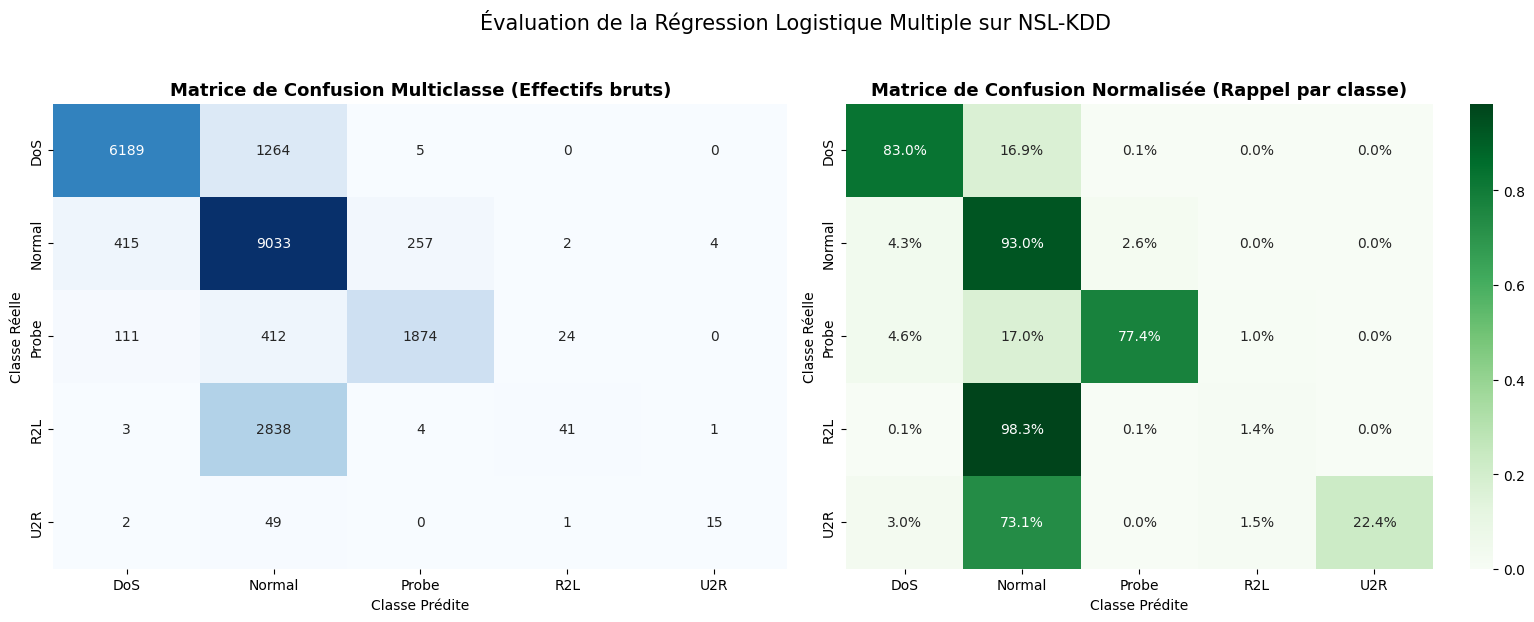

In [ ]:
cm_brute = confusion_matrix(y_test, y_pred, labels=classes)
cm_norm = confusion_matrix(y_test, y_pred, labels=classes, normalize='true')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Matrice brute
sns.heatmap(
    cm_brute,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=classes,
    yticklabels=classes,
    cbar=False,
    ax=axes[0]
)
axes[0].set_title('Matrice de Confusion Multiclasse (Effectifs bruts)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Classe Prédite')
axes[0].set_ylabel('Classe Réelle')

# Matrice normalisée (Taux de détection / Rappel)
sns.heatmap(
    cm_norm,
    annot=True,
    fmt='.1%',
    cmap='Greens',
    xticklabels=classes,
    yticklabels=classes,
    cbar=True,
    ax=axes[1]
)
axes[1].set_title('Matrice de Confusion Normalisée (Rappel par classe)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Classe Prédite')
axes[1].set_ylabel('Classe Réelle')

plt.suptitle('Évaluation de la Régression Logistique Multiple sur NSL-KDD', fontsize=15, y=1.03)
plt.tight_layout()
plt.show()